In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt


np.random.seed(7)
tf.random.set_seed(7)


num_notes = 40
sequence_length = 25
num_sequences = 1200
data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))

print("data.shape:", data.shape)

# Q. What do the two numbers in data.shape mean (rows vs columns)?
# Answer: The first number (1200) represents the number of sequences (samples/rows) in our dataset.
# The second number (25) represents the length of each sequence (columns/time-steps).

data.shape: (1200, 25)


In [5]:
# Step 2 — Build input/target pairs and one-hot encode
x_train_raw = data[:, :-1]
y_train_raw = data[:, 1:]

x_train = to_categorical(x_train_raw, num_classes=num_notes)
y_train = to_categorical(y_train_raw, num_classes=num_notes)

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

# Q. Why is the target the input shifted by one? What task does that set up?
# Answer: It sets up a next-step prediction task (sequence-to-sequence learning).
# At each time-step t, the network is trained to predict the element at time-step t+1.

x_train: (1200, 24, 40)
y_train: (1200, 24, 40)


In [6]:
# Step 3 — Build the Bidirectional LSTM model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Bidirectional, LSTM, TimeDistributed, Dense

model = Sequential([
    Input(shape=(24, 40)),
    Bidirectional(LSTM(100, return_sequences=True)),
    Bidirectional(LSTM(100, return_sequences=True)),
    TimeDistributed(Dense(40, activation='softmax'))
])

model.summary()

# Q. Each LSTM has 100 units, yet each Bidirectional layer outputs 200 features per step — why?
# And what does TimeDistributed do with the Dense layer?
# Answer: A Bidirectional layer concatenates the outputs of a forward LSTM (100 units) and a backward LSTM (100 units),
# resulting in 200 features. TimeDistributed applies the same Dense layer (sharing the weights) to every individual
# time-step of the sequence independently.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Step 4 — Compile and train
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

# Q. Why is categorical_crossentropy the correct loss here (think about the one-hot targets)?
# Answer: Categorical crossentropy measures the distance between two probability distributions.
# Since our targets are one-hot encoded vectors (multi-class distribution), this loss function is
# mathematically correct for optimizing multiclass classification predictions at each time-step.

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 143ms/step - accuracy: 0.0980 - loss: 3.6592 - val_accuracy: 0.1500 - val_loss: 3.6179
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.1365 - loss: 3.5388 - val_accuracy: 0.1078 - val_loss: 3.4121
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.1394 - loss: 3.2659 - val_accuracy: 0.1571 - val_loss: 3.1245
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.1820 - loss: 2.9758 - val_accuracy: 0.1993 - val_loss: 2.8398
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 161ms/step - accuracy: 0.2334 - loss: 2.6341 - val_accuracy: 0.2655 - val_loss: 2.4832
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.3107 - loss: 2.2584 - val_accuracy: 0.3458 - val_loss: 2.1025
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step - accuracy: 0.3895 - loss: 1.8890 - val_accuracy: 0.4224 - val_loss: 1.7564
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.4814 - loss: 1.5600 - val_accuracy: 0.516

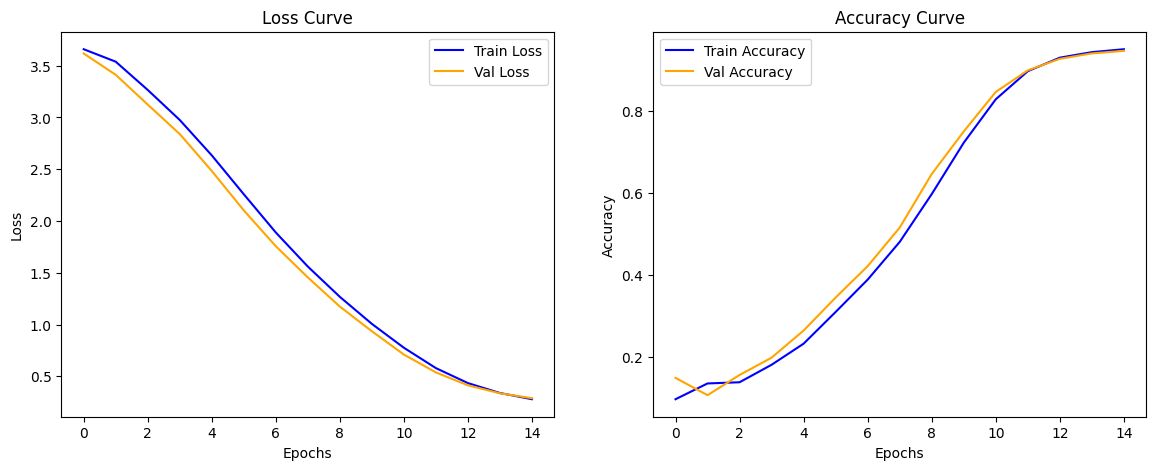

In [8]:
# Step 5 — Plot the training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(history.history['loss'], label='Train Loss', color='blue')
ax1.plot(history.history['val_loss'], label='Val Loss', color='orange')
ax1.set_title('Loss Curve')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy plot
ax2.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
ax2.set_title('Accuracy Curve')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.show()

# Q. Do the training and validation curves stay close together? What would a big gap between them have told you?
# Answer: Yes, they track each other closely. A big gap would indicate overfitting, meaning the model is memorizing
# the training set and failing to generalize to unseen validation data.

In [9]:
# Step 6 — Generate a new sequence (greedy)
def generate_music(model, start_sequence, num_generated_notes=40):
    current = start_sequence.copy()
    generated = []
    for _ in range(num_generated_notes):
        pred = model.predict(current, verbose=0)
        # Take the prediction from the last step (-1)
        new_note = np.argmax(pred[:, -1, :], axis=-1)[0]
        generated.append(new_note)

        # Prepare the new note's one-hot vector
        new_note_one_hot = to_categorical([new_note], num_classes=40).reshape(1, 1, 40)
        # Slide the window
        current = np.concatenate([current[:, 1:, :], new_note_one_hot], axis=1)
    return generated

# Seed with a random one-hot window of length 24
seed_seq = to_categorical(np.random.randint(0, 40, size=(1, 24)), num_classes=40)
generated_notes = generate_music(model, seed_seq, num_generated_notes=40)
print("Generated:", generated_notes)

# Q. At each step, which time-step’s prediction do you keep, and how do you update the input window for the next step?
# Answer: We keep the prediction corresponding to the very last time-step (-1). We update the input window by discarding
# the first step of the sequence and appending the newly predicted note at the end.

Generated: [np.int64(26), np.int64(26), np.int64(26), np.int64(26), np.int64(26), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35), np.int64(35)]


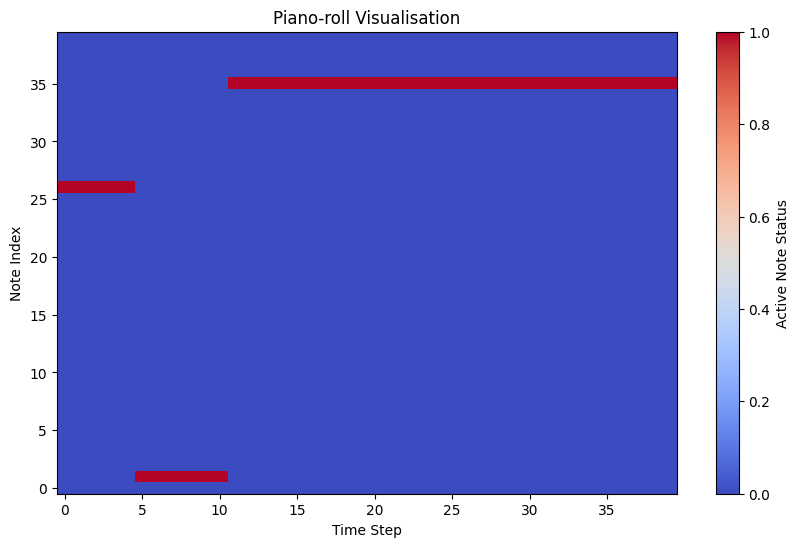

In [10]:
# Step 7 — Piano-roll visualisation
piano_roll = np.zeros((40, 40))
for t, note in enumerate(generated_notes):
    piano_roll[note, t] = 1

plt.figure(figsize=(10, 6))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower')
plt.title("Piano-roll Visualisation")
plt.xlabel("Time Step")
plt.ylabel("Note Index")
plt.colorbar(label='Active Note Status')
plt.show()

# Q. What does one column of the piano-roll represent, and why is exactly one cell active in each column?
# Answer: One column represents a single time-step in the generated sequence. Exactly one cell is active because at any
# given moment, the generator only outputs exactly one single active note (monophonic music generation).

In [12]:
# Q. Explain in one line how a bidirectional model can score so high on next-note prediction even with no real pattern.
# Answer: The bidirectional model achieves high accuracy because the backward pass has already read the future target notes (label leakage), allowing the network to copy future inputs rather than learning actual patterns.